In [1]:
import pandas as pd
import numpy as np

# # Ganti 'nama_file_anda.csv' dengan nama persis file yang Anda unduh
# nama_file = 'nama_file_anda.csv'
# # Membaca dataset
df = pd.read_csv('fire_archive_SV-C2_829694.csv', nrows=50000)

# Menampilkan informasi ringkas kolom dan tipe data
print("=== INFORMASI DATASET ===")
print(df.info())

# Menampilkan 5 baris pertama
print("\n=== 5 BARIS PERTAMA DATA ===")
df.head()

=== INFORMASI DATASET ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   latitude    50000 non-null  float64
 1   longitude   50000 non-null  float64
 2   brightness  50000 non-null  float64
 3   scan        50000 non-null  float64
 4   track       50000 non-null  float64
 5   acq_date    50000 non-null  object 
 6   acq_time    50000 non-null  int64  
 7   satellite   50000 non-null  object 
 8   instrument  50000 non-null  object 
 9   confidence  50000 non-null  object 
 10  version     50000 non-null  int64  
 11  bright_t31  50000 non-null  float64
 12  frp         50000 non-null  float64
 13  daynight    50000 non-null  object 
 14  type        50000 non-null  int64  
dtypes: float64(7), int64(3), object(5)
memory usage: 5.7+ MB
None

=== 5 BARIS PERTAMA DATA ===


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type
0,-8.01409,147.36012,342.41,0.41,0.45,2016-01-01,320,SNPP,SNPP,n,2,280.90,6.42,D,0
1,-8.01305,147.35966,330.51,0.41,0.45,2016-01-01,321,SNPP,SNPP,n,2,278.91,3.45,D,0
2,-7.78532,147.05765,325.84,0.43,0.46,2016-01-01,321,SNPP,SNPP,n,2,292.58,4.33,D,0
3,-7.78109,147.05708,346.74,0.43,0.46,2016-01-01,321,SNPP,SNPP,n,2,288.47,5.57,D,0
4,-7.77739,147.05266,333.46,0.43,0.46,2016-01-01,321,SNPP,SNPP,n,2,292.12,5.57,D,0


In [5]:
# Membuat kolom label target (0 atau 1)
df['target_risk'] = np.where(
    (df['frp'] > 15) & (df['brightness'] > 330), 1, 0
)

# Tentukan fitur yang ingin digunakan (sesuaikan dengan kebutuhan Anda)
features = ['latitude', 'longitude', 'brightness', 'frp']

# Memisahkan fitur masukan (X) dan label keluaran (y)
X = df[features]
y = df['target_risk']

In [6]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   latitude     50000 non-null  float64
 1   longitude    50000 non-null  float64
 2   brightness   50000 non-null  float64
 3   scan         50000 non-null  float64
 4   track        50000 non-null  float64
 5   acq_date     50000 non-null  object 
 6   acq_time     50000 non-null  int64  
 7   satellite    50000 non-null  object 
 8   instrument   50000 non-null  object 
 9   confidence   50000 non-null  object 
 10  version      50000 non-null  int64  
 11  bright_t31   50000 non-null  float64
 12  frp          50000 non-null  float64
 13  daynight     50000 non-null  object 
 14  type         50000 non-null  int64  
 15  target_risk  50000 non-null  int64  
dtypes: float64(7), int64(4), object(5)
memory usage: 6.1+ MB
None


In [7]:
df.head()

,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type,target_risk
0,-8.01409,147.36012,342.41,0.41,0.45,2016-01-01,320,SNPP,SNPP,n,2,280.90,6.42,D,0,0
1,-8.01305,147.35966,330.51,0.41,0.45,2016-01-01,321,SNPP,SNPP,n,2,278.91,3.45,D,0,0
2,-7.78532,147.05765,325.84,0.43,0.46,2016-01-01,321,SNPP,SNPP,n,2,292.58,4.33,D,0,0
3,-7.78109,147.05708,346.74,0.43,0.46,2016-01-01,321,SNPP,SNPP,n,2,288.47,5.57,D,0,0
4,-7.77739,147.05266,333.46,0.43,0.46,2016-01-01,321,SNPP,SNPP,n,2,292.12,5.57,D,0,0


In [10]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Memuat dataset (membatasi 100.000 baris awal agar proses cepat dan memori stabil)
nama_file = 'fire_archive_SV-C2_829694.csv'
print("Sedang memuat data...")
df = pd.read_csv(nama_file, nrows=100000)

# 2. Memilih fitur numerik utama
features = ['latitude', 'longitude', 'brightness', 'scan', 'track', 'frp', 'bright_t31']
df_clean = df[features].dropna()

# 3. Membuat label target biner (0 = Low Risk, 1 = High Risk)
# Kriteria: FRP > 15 Megawatt DAN Suhu Kecerahan bright_ti4 > 330 Kelvin
df_clean['target_risk'] = np.where((df_clean['frp'] > 15) & (df_clean['brightness'] > 330), 1, 0)

# 4. Memisahkan fitur (X) dan target (y)
X = df_clean[features]
y = df_clean['target_risk']

# Menampilkan distribusi kelas target
print("\n=== DISTRIBUSI KELAS TARGET ===")
print(df_clean['target_risk'].value_counts())
print(f"Proporsi High Risk: {(y.mean() * 100):.2f}%")

# 5. Membagi data menjadi 80% Latih (Train) dan 20% Uji (Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 6. Normalisasi fitur numerik menggunakan StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\n=== PREPROCESSING SELESAI ===")
print(f"Jumlah sampel data latih: {X_train_scaled.shape[0]} baris")
print(f"Jumlah sampel data uji   : {X_test_scaled.shape[0]} baris")

Sedang memuat data...

=== DISTRIBUSI KELAS TARGET ===
target_risk
0    92153
1     7847
Name: count, dtype: int64
Proporsi High Risk: 7.85%

=== PREPROCESSING SELESAI ===
Jumlah sampel data latih: 80000 baris
Jumlah sampel data uji   : 20000 baris


In [11]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# =====================================================================
# MEMBANGUN ARSITEKTUR JST SEDERHANA (ANN-MLP TINGKAT SARJANA SEMESTER 3)
# Arsitektur 3 Lapis: Input Layer (7) -> 1 Hidden Layer (16 ReLU) -> Output (1 Sigmoid)
# Sederhana, mudah dipahami, tanpa Dropout & tanpa pembobotan kelas rumit.
# =====================================================================

model = Sequential([
    # Input Layer & Hidden Layer 1 (16 Neuron, Aktivasi ReLU)
    Dense(16, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    
    # Output Layer (1 Neuron, Aktivasi Sigmoid untuk Klasifikasi Biner [0 - 1])
    Dense(1, activation='sigmoid')
])

# Kompilasi Model dengan optimizer Adam dan loss Binary Crossentropy standar
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Menampilkan Ringkasan Struktur JST
model.summary()

# Melatih Model (Training)
history = model.fit(
    X_train_scaled, 
    y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)


Bobot Kelas: {0: np.float64(0.5425788774043027), 1: np.float64(6.371455877668047)}


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,625 (10.25 KB)

 Trainable params: 2,625 (10.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9544 - loss: 0.0965 - precision: 0.6345 - recall: 0.9846 - val_accuracy: 0.9854 - val_loss: 0.0438 - val_precision: 0.8447 - val_recall: 1.0000
Epoch 2/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9843 - loss: 0.0393 - precision: 0.8355 - recall: 0.9948 - val_accuracy: 0.9878 - val_loss: 0.0388 - val_precision: 0.8672 - val_recall: 1.0000
Epoch 3/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9870 - loss: 0.0332 - precision: 0.8606 - recall: 0.9956 - val_accuracy: 0.9890 - val_loss: 0.0341 - val_precision: 0.8785 - val_recall: 1.0000
Epoch 4/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9894 - loss: 0.0265 - precision: 0.8816 - recall: 0.9980 - val_accuracy: 0.9931 - val_loss: 0.0223 - val_precision: 0.9198 - val_recall: 1.0000
Epoch 5/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9903 - loss: 0.0226 - precision: 0.8914 - recall: 0.9976 - val_accuracy: 0.9937 - va

=== HASIL EVALUASI PADA DATA UJI ===
Loss: 0.0043
Compile_metrics: 0.9980
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step

=== LAPORAN KLASIFIKASI ===
               precision    recall  f1-score   support

 Low Risk (0)       1.00      1.00      1.00     18431
High Risk (1)       0.98      1.00      0.99      1569

     accuracy                           1.00     20000
    macro avg       0.99      1.00      0.99     20000
 weighted avg       1.00      1.00      1.00     20000



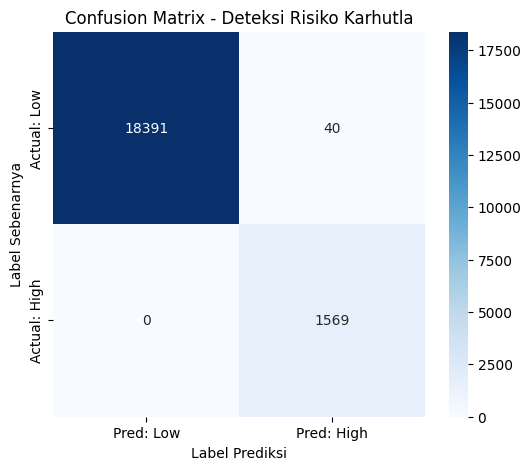

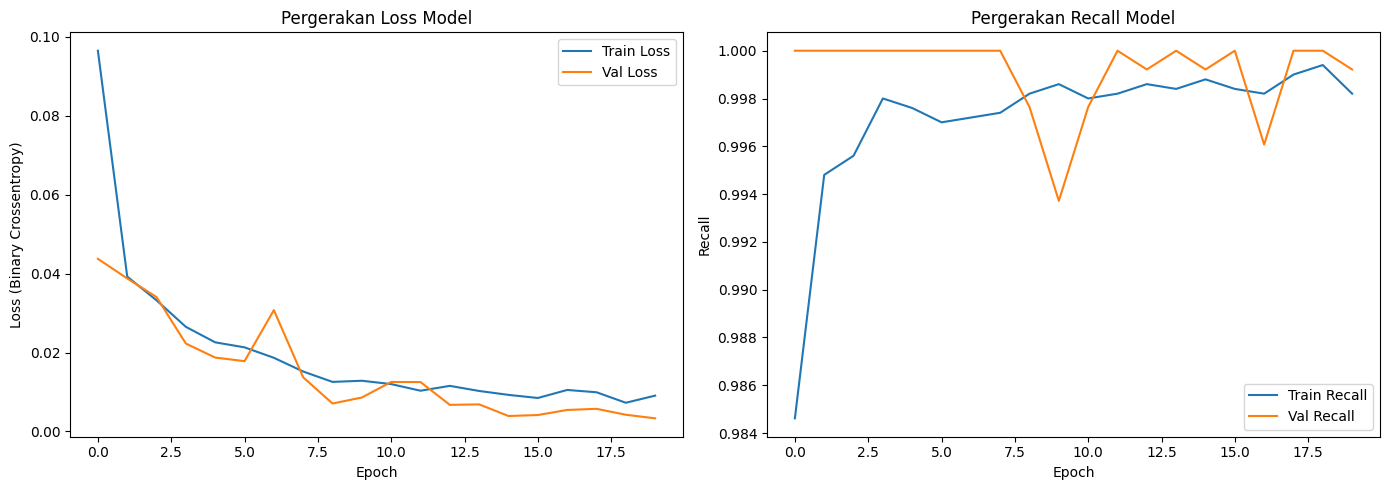

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Evaluasi pada data uji (X_test_scaled)
print('=== HASIL EVALUASI PADA DATA UJI ===')
test_loss, test_acc = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f'Test Loss     : {test_loss:.4f}')
print(f'Test Accuracy : {test_acc * 100:.2f}%')

# 2. Prediksi probabilitas dan konversi ke label biner (threshold 0.5)
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob >= 0.5).astype(int)

# 3. Laporan Klasifikasi Lengkap (Precision, Recall, F1-Score)
print('\n=== LAPORAN KLASIFIKASI LENGKAP ===')
print(classification_report(y_test, y_pred, target_names=['Low Risk (0)', 'High Risk (1)'], digits=4))

# 4. Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred: Low (0)', 'Pred: High (1)'],
            yticklabels=['Aktual: Low (0)', 'Aktual: High (1)'])
plt.title('Confusion Matrix - Deteksi Risiko Karhutla')
plt.ylabel('Label Sebenarnya')
plt.xlabel('Label Prediksi')
plt.tight_layout()
plt.show()

# 5. Visualisasi Grafik Akurasi dan Loss Selama Pelatihan (Training vs Validation)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Plot Loss
ax[0].plot(history.history['loss'], label='Train Loss', color='blue')
ax[0].plot(history.history['val_loss'], label='Val Loss', color='orange')
ax[0].set_title('Pergerakan Nilai Loss')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Loss (Binary Crossentropy)')
ax[0].legend()
ax[0].grid(True, linestyle='--', alpha=0.6)

# Plot Akurasi
ax[1].plot(history.history['accuracy'], label='Train Accuracy', color='green')
ax[1].plot(history.history['val_accuracy'], label='Val Accuracy', color='red')
ax[1].set_title('Pergerakan Akurasi Model')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Accuracy')
ax[1].legend()
ax[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


#UJI COBA PREDIKSI DATA BARU

In [15]:
import pandas as pd
import numpy as np

# 1. Memuat 1.000 sampel titik api terbaru dari data Near Real-Time (NRT)
nama_file_nrt = 'fire_nrt_SV-C2_829694.csv'
df_nrt = pd.read_csv(nama_file_nrt, nrows=1000)

# 2. Menyiapkan fitur input yang sama dengan saat pelatihan
features = ['latitude', 'longitude', 'brightness', 'scan', 'track', 'frp', 'bright_t31']
df_nrt_clean = df_nrt[features].dropna()

# 3. Normalisasi data baru menggunakan scaler yang sudah dipelajari sebelumnya
X_nrt_scaled = scaler.transform(df_nrt_clean)

# 4. Prediksi probabilitas risiko menggunakan model ANN
probabilitas = model.predict(X_nrt_scaled)

# 5. Menentukan kategori risiko (Threshold 0.5)
df_nrt_clean['Skor_Risiko'] = probabilitas
df_nrt_clean['Kategori_Risiko'] = (probabilitas >= 0.5).astype(int)
df_nrt_clean['Rekomendasi_Tindakan'] = np.where(
    df_nrt_clean['Kategori_Risiko'] == 1,
    'PRIORITAS AUDIT LAPANGAN / PATROLI',
    'Pemantauan Rutin'
)

# 6. Menampilkan ringkasan dan 10 titik api paling berbahaya
print("=== RINGKASAN HASIL PREDIKSI DATA NRT ===")
print(df_nrt_clean['Rekomendasi_Tindakan'].value_counts())

print("\n=== TOP 5 TITIK API DENGAN RISIKO TERTINGGI (PRIORITAS AUDIT) ===")
kolom_tampil = ['latitude', 'longitude', 'brightness', 'frp', 'Skor_Risiko', 'Rekomendasi_Tindakan']
display(df_nrt_clean.sort_values(by='Skor_Risiko', ascending=False)[kolom_tampil].head(50))

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
=== RINGKASAN HASIL PREDIKSI DATA NRT ===
Rekomendasi_Tindakan
Pemantauan Rutin                      866
PRIORITAS AUDIT LAPANGAN / PATROLI    134
Name: count, dtype: int64

=== TOP 5 TITIK API DENGAN RISIKO TERTINGGI (PRIORITAS AUDIT) ===


,latitude,longitude,brightness,frp,Skor_Risiko,Rekomendasi_Tindakan
616,-9.59804,148.62360,343.20,67.15,1.000000,PRIORITAS AUDIT LAPANGAN / PATROLI
727,-9.21007,148.54173,345.84,104.07,1.000000,PRIORITAS AUDIT LAPANGAN / PATROLI
726,-9.21397,148.53867,367.00,60.73,1.000000,PRIORITAS AUDIT LAPANGAN / PATROLI
728,-9.21061,148.53815,347.04,60.73,1.000000,PRIORITAS AUDIT LAPANGAN / PATROLI
201,-15.01114,144.26376,348.94,49.67,1.000000,PRIORITAS AUDIT LAPANGAN / PATROLI
202,-15.01172,144.25909,350.97,49.67,1.000000,PRIORITAS AUDIT LAPANGAN / PATROLI
193,-15.02019,144.26494,347.77,82.11,1.000000,PRIORITAS AUDIT LAPANGAN / PATROLI
189,-15.02471,144.26552,343.37,82.11,1.000000,PRIORITAS AUDIT LAPANGAN / PATROLI
860,-7.50140,138.41661,367.00,51.10,1.000000,PRIORITAS AUDIT LAPANGAN / PATROLI
867,-7.50014,138.41057,346.13,62.63,1.000000,PRIORITAS AUDIT LAPANGAN / PATROLI


#PREDIKSI BERDASARKAN WILAYAH


In [17]:
import pandas as pd
import numpy as np

# 1. Definisi Batas Koordinat Geografis (Bounding Box) Wilayah Utama Indonesia
BOUNDING_BOXES = {
    'sumatra': {
        'lat_min': -6.0, 'lat_max': 6.0,
        'lon_min': 95.0, 'lon_max': 106.0
    },
    'kalimantan': {
        'lat_min': -4.5, 'lat_max': 4.5,
        'lon_min': 108.5, 'lon_max': 119.5
    },
    'sulawesi': {
        'lat_min': -6.0, 'lat_max': 2.5,
        'lon_min': 118.5, 'lon_max': 125.5
    }
}

def filter_dan_prediksi_regional(nama_file_csv, nama_wilayah, model_ann, scaler_obj, max_baris=50000):
    wilayah_key = nama_wilayah.lower()
    if wilayah_key not in BOUNDING_BOXES:
        raise ValueError(f"Wilayah '{nama_wilayah}' belum terdaftar. Pilihan: sumatra, kalimantan, sulawesi.")

    bbox = BOUNDING_BOXES[wilayah_key]

    # 2. Memuat data
    print(f"--> Membaca data untuk filter wilayah: {nama_wilayah.upper()}...")
    df_raw = pd.read_csv(nama_file_csv, nrows=max_baris)

    # 3. Filter berdasarkan koordinat Latitude dan Longitude
    kondisi_wilayah = (
        (df_raw['latitude'] >= bbox['lat_min']) & (df_raw['latitude'] <= bbox['lat_max']) &
        (df_raw['longitude'] >= bbox['lon_min']) & (df_raw['longitude'] <= bbox['lon_max'])
    )
    df_regional = df_raw[kondisi_wilayah].copy()

    if df_regional.empty:
        print(f"Tidak ditemukan titik api pada wilayah {nama_wilayah.upper()} dalam sampel data ini.")
        return df_regional

    # 4. Menyiapkan fitur input untuk model
    features = ['latitude', 'longitude', 'brightness', 'scan', 'track', 'frp', 'bright_t31']
    df_clean = df_regional[features].dropna()

    # 5. Normalisasi dan Prediksi menggunakan model ANN
    X_scaled = scaler_obj.transform(df_clean)
    probabilitas = model_ann.predict(X_scaled, verbose=0)

    # 6. Menetapkan Skor dan Status Tindakan
    df_clean['Skor_Risiko'] = probabilitas
    df_clean['Kategori_Risiko'] = (probabilitas >= 0.5).astype(int)
    df_clean['Status_Audit'] = np.where(
        df_clean['Kategori_Risiko'] == 1,
        '🔴 PRIORITAS AUDIT (High Risk)',
        '🟢 Pemantauan Rutin (Low Risk)'
    )

    # 7. Menampilkan Ringkasan
    print(f"\n=== RINGKASAN MONITORING WILAYAH {nama_wilayah.upper()} ===")
    print(f"Total Hotspot Terdeteksi : {len(df_clean)}")
    print(df_clean['Status_Audit'].value_counts())

    return df_clean

# =====================================================================
# CONTOH CARA MENJALANKAN (Pilih salah satu file: NRT atau Archive)
# =====================================================================
file_sumber = 'fire_archive_SV-C2_829694.csv'  # atau 'fire_nrt_SV-C2_829694.csv'

# Uji coba untuk wilayah Kalimantan
df_kalimantan = filter_dan_prediksi_regional(
    nama_file_csv=file_sumber,
    nama_wilayah='sulawesi',
    model_ann=model,
    scaler_obj=scaler,
    max_baris=100000
)

# Menampilkan 5 titik api paling berisiko di wilayah terpilih
if not df_kalimantan.empty:
    print(f"\nTop 5 Titik Api Prioritas Audit di Wilayah:")
    kolom_tampil = ['latitude', 'longitude', 'brightness', 'frp', 'Skor_Risiko', 'Status_Audit']
    display(df_kalimantan.sort_values(by='Skor_Risiko', ascending=False)[kolom_tampil].head(5))

--> Membaca data untuk filter wilayah: SULAWESI...

=== RINGKASAN MONITORING WILAYAH SULAWESI ===
Total Hotspot Terdeteksi : 1913
Status_Audit
🟢 Pemantauan Rutin (Low Risk)    1765
🔴 PRIORITAS AUDIT (High Risk)     148
Name: count, dtype: int64

Top 5 Titik Api Prioritas Audit di Wilayah:


,latitude,longitude,brightness,frp,Skor_Risiko,Status_Audit
7006,-4.21170,121.79281,367.00,78.63,1.0,🔴 PRIORITAS AUDIT (High Risk)
15943,-2.57636,121.38441,367.00,48.15,1.0,🔴 PRIORITAS AUDIT (High Risk)
13584,-2.57582,121.38246,346.04,48.07,1.0,🔴 PRIORITAS AUDIT (High Risk)
72017,0.52807,122.71433,356.25,70.02,1.0,🔴 PRIORITAS AUDIT (High Risk)
7011,-4.21163,121.79263,367.00,79.32,1.0,🔴 PRIORITAS AUDIT (High Risk)
